# PyTorch Fundamentals: de los tensores a una neurona

Este notebook recorre los fundamentos de PyTorch en orden, y termina construyendo y entrenando una **neurona simple** de tres formas distintas.

**Contenido**

1. Preparación e imports
2. Tensores: qué son y cómo se crean
3. Atributos de un tensor: `shape`, `dtype`, `device`
4. Indexado y slicing
5. Cambiar la forma: `reshape`, `view`, `squeeze`, `unsqueeze`, `permute`, `cat`, `stack`
6. Operaciones: elemento a elemento, broadcasting, producto matricial, agregaciones
7. Puente con NumPy
8. CPU y GPU
9. Autograd: derivadas automáticas
10. La neurona simple
    - 10.1 Qué es una neurona
    - 10.2 Neurona a mano, solo con tensores
    - 10.3 Entrenarla a mano con descenso de gradiente
    - 10.4 La misma neurona con `nn.Linear`, una función de pérdida y un optimizador
    - 10.5 Neurona con activación (sigmoide) para clasificar
11. Guardar y cargar un modelo
12. Resumen y ejercicios

Ejecuta las celdas en orden: varias dependen de variables definidas más arriba.

## 1. Preparación e imports

Necesitas `torch` y `matplotlib` (para los gráficos) instalados en el kernel que elijas.

- `torch` es la librería principal.
- `torch.nn` contiene las piezas para construir redes (capas, funciones de pérdida).

In [1]:
import torch
from torch import nn
import numpy as np
import matplotlib.pyplot as plt

print("Versión de PyTorch:", torch.__version__)
print("¿Hay GPU con CUDA?:", torch.cuda.is_available())

Versión de PyTorch: 2.11.0+cpu
¿Hay GPU con CUDA?: False


Fijamos una **semilla** para que los números aleatorios sean los mismos cada vez que ejecutes el notebook. Así tus resultados coinciden con los comentarios.

In [2]:
torch.manual_seed(42)

## 2. Tensores: qué son y cómo se crean

Un **tensor** es un arreglo de números con cualquier cantidad de dimensiones. Es la estructura de datos central de PyTorch: los datos, los pesos de la red y los gradientes son todos tensores.

| Dimensiones | Nombre | Ejemplo |
|---|---|---|
| 0 | escalar | una temperatura: `25.0` |
| 1 | vector | las notas de un alumno |
| 2 | matriz | una tabla de datos (filas = ejemplos, columnas = características) |
| 3 o más | tensor | una imagen a color: canales x alto x ancho |

Se parece a un arreglo de NumPy, con dos diferencias clave: puede vivir en la **GPU** y puede **calcular derivadas automáticamente**.

In [3]:
escalar = torch.tensor(7.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matriz = torch.tensor([[1.0, 2.0, 3.0],
                       [4.0, 5.0, 6.0]])
tensor3d = torch.tensor([[[1, 2], [3, 4]],
                         [[5, 6], [7, 8]]])

for nombre, t in [("escalar", escalar), ("vector", vector), ("matriz", matriz), ("tensor3d", tensor3d)]:
    print(f"{nombre:9s} dimensiones={t.ndim}  forma={tuple(t.shape)}")

escalar   dimensiones=0  forma=()
vector    dimensiones=1  forma=(3,)
matriz    dimensiones=2  forma=(2, 3)
tensor3d  dimensiones=3  forma=(2, 2, 2)


Además de escribir los valores a mano, hay funciones para crear tensores ya rellenos. Las vas a usar todo el tiempo.

In [4]:
print("zeros:\n", torch.zeros(2, 3))
print("ones:\n", torch.ones(2, 3))
print("rand (uniforme entre 0 y 1):\n", torch.rand(2, 3))
print("randn (normal, media 0 y desviación 1):\n", torch.randn(2, 3))
print("arange:", torch.arange(0, 10, 2))
print("linspace:", torch.linspace(0, 1, 5))

# Las versiones *_like copian la forma de otro tensor
print("zeros_like:\n", torch.zeros_like(matriz))

zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
ones:
 tensor([[1., 1., 1.],
        [1., 1., 1.]])
rand (uniforme entre 0 y 1):
 tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009]])
randn (normal, media 0 y desviación 1):
 tensor([[ 1.1561,  0.3965, -2.4661],
        [ 0.3623,  0.3765, -0.1808]])
arange: tensor([0, 2, 4, 6, 8])
linspace: tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])
zeros_like:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])


## 3. Atributos de un tensor: `shape`, `dtype`, `device`

Cada tensor tiene tres atributos que conviene revisar cuando algo falla. La mayoría de los errores en PyTorch vienen de que alguno de los tres no es el que esperabas.

- **`shape`**: la forma, cuántos elementos hay en cada dimensión.
- **`dtype`**: el tipo de dato. Por defecto los decimales son `float32` y los enteros `int64`.
- **`device`**: dónde vive el tensor, `cpu` o `cuda` (GPU).

In [5]:
t = torch.rand(3, 4)
print("shape :", t.shape)
print("dtype :", t.dtype)
print("device:", t.device)

shape : torch.Size([3, 4])
dtype : torch.float32
device: cpu


El `dtype` se puede cambiar. Los pesos de una red son `float32`, así que si tus datos llegan como enteros hay que convertirlos antes de usarlos.

In [6]:
enteros = torch.tensor([1, 2, 3])
print(enteros.dtype)

decimales = enteros.float()          # atajo para .to(torch.float32)
print(decimales, decimales.dtype)

print(decimales.to(torch.float64).dtype)

torch.int64
tensor([1., 2., 3.]) torch.float32
torch.float64


## 4. Indexado y slicing

Funciona igual que en NumPy: `tensor[fila, columna]`, y `:` significa "todo en esta dimensión".

In [7]:
m = torch.arange(1, 13).reshape(3, 4)
print(m)

print("primera fila      :", m[0])
print("última columna    :", m[:, -1])
print("elemento [1, 2]   :", m[1, 2])
print("filas 0-1, cols 1-2:\n", m[0:2, 1:3])

# Indexado con una condición (máscara booleana)
print("mayores que 6     :", m[m > 6])

tensor([[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]])
primera fila      : tensor([1, 2, 3, 4])
última columna    : tensor([ 4,  8, 12])
elemento [1, 2]   : tensor(7)
filas 0-1, cols 1-2:
 tensor([[2, 3],
        [6, 7]])
mayores que 6     : tensor([ 7,  8,  9, 10, 11, 12])


Un tensor de un solo elemento se convierte a número de Python con `.item()`. Es lo que se usa para imprimir la pérdida durante el entrenamiento.

In [8]:
valor = m[1, 2]
print(valor, "->", valor.item(), type(valor.item()))

tensor(7) -> 7 <class 'int'>


## 5. Cambiar la forma

Las capas de una red esperan los datos con una forma concreta, así que reacomodar tensores es rutina. Ninguna de estas operaciones cambia los valores, solo cómo se organizan.

- **`reshape` / `view`**: reorganizan los mismos elementos en otra forma. El total de elementos debe coincidir. `-1` significa "calcula tú esta dimensión".
- **`unsqueeze(dim)`**: agrega una dimensión de tamaño 1.
- **`squeeze()`**: quita las dimensiones de tamaño 1.
- **`permute`**: reordena las dimensiones.

In [9]:
x = torch.arange(12)
print("original   :", x.shape)
print("reshape 3x4:", x.reshape(3, 4).shape)
print("reshape -1 :", x.reshape(2, -1).shape)   # el -1 se calcula solo: 6

columna = x.unsqueeze(1)
print("unsqueeze(1):", columna.shape)           # de [12] a [12, 1]
print("squeeze     :", columna.squeeze().shape) # de vuelta a [12]

imagen = torch.rand(3, 32, 64)                  # canales, alto, ancho
print("permute     :", imagen.permute(1, 2, 0).shape)  # alto, ancho, canales

original   : torch.Size([12])
reshape 3x4: torch.Size([3, 4])
reshape -1 : torch.Size([2, 6])
unsqueeze(1): torch.Size([12, 1])
squeeze     : torch.Size([12])
permute     : torch.Size([32, 64, 3])


`unsqueeze` importa mucho para lo que viene: `nn.Linear` espera los datos como **[número de ejemplos, número de características]**. Un vector de 50 valores tiene forma `[50]`, y hay que pasarlo a `[50, 1]` (50 ejemplos, 1 característica).

Para unir tensores:

- **`cat`** los pega a lo largo de una dimensión que ya existe.
- **`stack`** crea una dimensión nueva.

In [10]:
a = torch.tensor([1, 2, 3])
b = torch.tensor([4, 5, 6])

print("cat  :", torch.cat([a, b]), torch.cat([a, b]).shape)
print("stack:\n", torch.stack([a, b]), torch.stack([a, b]).shape)

cat  : tensor([1, 2, 3, 4, 5, 6]) torch.Size([6])
stack:
 tensor([[1, 2, 3],
        [4, 5, 6]]) torch.Size([2, 3])


## 6. Operaciones

### Elemento a elemento

Las operaciones aritméticas normales se aplican posición por posición.

In [11]:
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([10.0, 20.0, 30.0])

print("a + b :", a + b)
print("a * b :", a * b)     # multiplica posición por posición, NO es producto matricial
print("a ** 2:", a ** 2)
print("a * 10:", a * 10)

a + b : tensor([11., 22., 33.])
a * b : tensor([10., 40., 90.])
a ** 2: tensor([1., 4., 9.])
a * 10: tensor([10., 20., 30.])


### Broadcasting

Cuando las formas no coinciden, PyTorch intenta "estirar" el tensor más pequeño para que calcen. En `a * 10` de arriba, el 10 se estiró a `[10, 10, 10]`.

Regla: se comparan las formas de derecha a izquierda, y dos dimensiones son compatibles si son iguales o si una de ellas es 1.

In [12]:
matriz = torch.ones(3, 4)
fila = torch.tensor([1.0, 2.0, 3.0, 4.0])      # forma [4]

print(matriz + fila)                            # la fila se repite en las 3 filas

columna = torch.tensor([[10.0], [20.0], [30.0]])  # forma [3, 1]
print(matriz + columna)                         # la columna se repite en las 4 columnas

tensor([[2., 3., 4., 5.],
        [2., 3., 4., 5.],
        [2., 3., 4., 5.]])
tensor([[11., 11., 11., 11.],
        [21., 21., 21., 21.],
        [31., 31., 31., 31.]])


### Producto matricial

Es la operación que hace una neurona por dentro. Se escribe con `@` o `torch.matmul`.

Regla de formas: `[n, m] @ [m, p]` da `[n, p]`. Las dimensiones **interiores** deben coincidir. Si no coinciden vas a ver el error `mat1 and mat2 shapes cannot be multiplied`, el más frecuente al empezar.

In [13]:
A = torch.rand(2, 3)
B = torch.rand(3, 4)

C = A @ B
print("[2, 3] @ [3, 4] ->", C.shape)

# Producto punto entre dos vectores: suma de los productos posición por posición
v = torch.tensor([1.0, 2.0, 3.0])
w = torch.tensor([4.0, 5.0, 6.0])
print("producto punto:", v @ w)        # 1*4 + 2*5 + 3*6 = 32

# .T traspone (intercambia filas y columnas); sirve para hacer calzar las formas
print("A.T:", A.T.shape)

[2, 3] @ [3, 4] -> torch.Size([2, 4])
producto punto: tensor(32.)
A.T: torch.Size([3, 2])


### Agregaciones

Resumen un tensor en menos valores. El argumento `dim` indica **qué dimensión se colapsa**.

In [14]:
m = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])

print("suma total        :", m.sum())
print("media total       :", m.mean())
print("suma por columna  :", m.sum(dim=0))     # colapsa las filas
print("suma por fila     :", m.sum(dim=1))     # colapsa las columnas
print("máximo            :", m.max())
print("posición del máx. :", m.argmax())       # índice en el tensor aplanado
print("argmax por fila   :", m.argmax(dim=1))

suma total        : tensor(21.)
media total       : tensor(3.5000)
suma por columna  : tensor([5., 7., 9.])
suma por fila     : tensor([ 6., 15.])
máximo            : tensor(6.)
posición del máx. : tensor(5)
argmax por fila   : tensor([2, 2])


## 7. Puente con NumPy

Se puede pasar de NumPy a PyTorch y de vuelta.

Dos cosas a tener presentes:

- NumPy usa `float64` por defecto y PyTorch `float32`. Al convertir, el tensor hereda `float64`, y eso choca con los pesos de una red. Conviene añadir `.float()`.
- En CPU, `torch.from_numpy` y `.numpy()` **comparten la memoria**: si cambias uno, cambia el otro.

In [15]:
arreglo = np.array([1.0, 2.0, 3.0])
tensor = torch.from_numpy(arreglo)
print(tensor, tensor.dtype)            # float64, heredado de NumPy
print(tensor.float().dtype)            # float32, lo que espera una red

# Comparten memoria: modificar el arreglo modifica el tensor
arreglo[0] = 99.0
print("tensor tras cambiar el arreglo:", tensor)

# De vuelta a NumPy
print(torch.ones(3).numpy())

tensor([1., 2., 3.], dtype=torch.float64) torch.float64
torch.float32
tensor tras cambiar el arreglo: tensor([99.,  2.,  3.], dtype=torch.float64)
[1. 1. 1.]


## 8. CPU y GPU

Las GPU hacen muchas operaciones en paralelo, por eso entrenar redes grandes es mucho más rápido en ellas. El patrón estándar es escribir el código de modo que funcione en cualquiera de las dos:

In [16]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Usando:", device)

t = torch.rand(2, 3)
t = t.to(device)        # .to() devuelve una copia en el dispositivo indicado
print(t.device)

Usando: cpu
cpu


Regla importante: para operar entre dos tensores, **ambos deben estar en el mismo dispositivo**. Lo mismo vale para un modelo y sus datos. Si no, aparece el error `Expected all tensors to be on the same device`.

Otro detalle: NumPy solo trabaja en CPU, así que un tensor en GPU hay que traerlo con `.cpu()` antes de llamar a `.numpy()`.

En el resto del notebook usamos CPU: los ejemplos son tan pequeños que la GPU no aporta nada.

## 9. Autograd: derivadas automáticas

Entrenar una red consiste en ajustar sus pesos para reducir un error. Para saber **en qué dirección** mover cada peso se necesita la derivada del error respecto de ese peso: el **gradiente**.

PyTorch calcula esas derivadas solo. Si un tensor tiene `requires_grad=True`, PyTorch registra todas las operaciones que se hacen con él. Al llamar a `.backward()` recorre ese registro hacia atrás y deja la derivada en `.grad`.

Ejemplo: $y = x^2 + 3x$. Su derivada es $\frac{dy}{dx} = 2x + 3$, que en $x = 2$ vale $7$.

In [17]:
x = torch.tensor(2.0, requires_grad=True)
y = x ** 2 + 3 * x

y.backward()            # calcula dy/dx

print("y     =", y.item())
print("dy/dx =", x.grad.item())    # 2*2 + 3 = 7

y     = 10.0
dy/dx = 7.0


### Los gradientes se acumulan

Cada llamada a `.backward()` **suma** al gradiente que ya había, no lo reemplaza. Por eso en todo ciclo de entrenamiento hay que ponerlos en cero en cada paso. Olvidarlo es un error clásico: el modelo no falla, pero aprende mal.

In [18]:
x = torch.tensor(2.0, requires_grad=True)

for paso in range(3):
    y = x ** 2 + 3 * x
    y.backward()
    print(f"paso {paso}: x.grad = {x.grad.item()}")   # 7, 14, 21: se va sumando

x.grad.zero_()
print("tras zero_():", x.grad.item())

paso 0: x.grad = 7.0
paso 1: x.grad = 14.0
paso 2: x.grad = 21.0
tras zero_(): 0.0


### Apagar el registro: `torch.no_grad()`

Registrar operaciones cuesta memoria y tiempo. Cuando no vas a derivar (al actualizar los pesos a mano, o al usar el modelo ya entrenado para predecir) se desactiva con `torch.no_grad()`.

In [19]:
x = torch.tensor(2.0, requires_grad=True)

y = x * 2
print("con registro   :", y.requires_grad)

with torch.no_grad():
    y = x * 2
print("dentro de no_grad:", y.requires_grad)

con registro   : True
dentro de no_grad: False


## 10. La neurona simple

### 10.1 Qué es una neurona

Una neurona artificial hace dos cosas:

1. **Combinación lineal**: multiplica cada entrada por un **peso**, suma todo y añade un **sesgo** (bias).

$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$$

2. **Activación** (opcional): pasa ese resultado por una función $f$ para obtener la salida.

$$\hat{y} = f(z)$$

Los **pesos** `w` dicen cuánto importa cada entrada. El **sesgo** `b` desplaza el resultado. Ambos son los **parámetros**: los números que la neurona aprende.

Con una sola entrada y sin activación, la neurona es $\hat{y} = w x + b$: la ecuación de una recta. Aprender significa encontrar la pendiente `w` y el corte `b` que mejor se ajustan a los datos.

### 10.2 Neurona a mano, solo con tensores

Antes de usar las herramientas de `torch.nn`, construimos la neurona con las operaciones que ya vimos, para ver que no hay nada oculto.

In [20]:
# Una neurona con 3 entradas
x = torch.tensor([1.0, 2.0, 3.0])       # entradas
w = torch.tensor([0.5, -1.0, 2.0])      # un peso por entrada
b = torch.tensor(0.1)                   # sesgo

z = x @ w + b                           # combinación lineal (producto punto + sesgo)
print("z =", z.item())                  # 1*0.5 + 2*(-1) + 3*2 + 0.1 = 4.6

salida = torch.sigmoid(z)               # activación sigmoide: aplasta z al rango (0, 1)
print("salida con sigmoide =", salida.item())

z = 4.599999904632568
salida con sigmoide = 0.9900481700897217


Esa neurona tiene pesos elegidos a mano, así que no sabe hacer nada útil. Lo interesante es que los **aprenda** a partir de datos.

### 10.3 Entrenarla a mano con descenso de gradiente

**El problema.** Generamos datos que siguen la recta $y = 2x + 1$ con algo de ruido. La neurona no conoce el 2 ni el 1: tiene que descubrirlos mirando los datos.

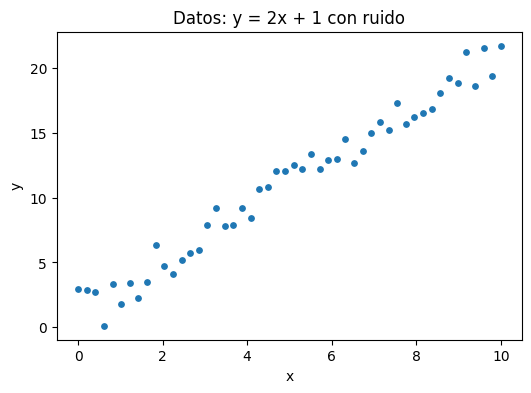

In [21]:
torch.manual_seed(42)

X = torch.linspace(0, 10, 50)                 # 50 valores de entrada
y = 2 * X + 1 + torch.randn(50) * 1.0         # recta real + ruido

plt.figure(figsize=(6, 4))
plt.scatter(X, y, s=15)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datos: y = 2x + 1 con ruido")
plt.show()

**El plan.** El entrenamiento repite cuatro pasos:

1. **Predicción** (forward): calcular $\hat{y} = w x + b$ con los parámetros actuales.
2. **Pérdida** (loss): medir qué tan mal estuvo. Usamos el error cuadrático medio (MSE): el promedio de $(\hat{y} - y)^2$.
3. **Gradientes** (backward): calcular cuánto cambia la pérdida si se mueve `w` o `b`.
4. **Actualización**: mover cada parámetro un poco en la dirección contraria a su gradiente.

$$w \leftarrow w - \text{lr} \cdot \frac{\partial L}{\partial w}$$

`lr` es la **tasa de aprendizaje** (learning rate): el tamaño del paso. Muy grande y el entrenamiento se vuelve inestable; muy pequeña y avanza lento.

Cada pasada completa por los datos se llama **época**.

In [22]:
# Parámetros: parten en valores arbitrarios y PyTorch debe seguirles la pista
w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

lr = 0.01
epocas = 1000
historial_manual = []

for epoca in range(epocas):
    # 1. Predicción
    y_pred = w * X + b

    # 2. Pérdida (MSE)
    loss = ((y_pred - y) ** 2).mean()

    # 3. Gradientes
    loss.backward()

    # 4. Actualización, sin registrar estas operaciones
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    # Poner los gradientes en cero para la siguiente vuelta
    w.grad.zero_()
    b.grad.zero_()

    historial_manual.append(loss.item())
    if epoca % 200 == 0:
        print(f"época {epoca:4d}  pérdida={loss.item():8.4f}  w={w.item():.3f}  b={b.item():.3f}")

print(f"\nAprendido: w={w.item():.3f}, b={b.item():.3f}   (real: w=2, b=1)")

época    0  pérdida=158.7337  w=1.456  b=0.222


época  200  pérdida=  1.0998  w=2.039  b=0.827
época  400  pérdida=  1.0808  w=2.011  b=1.012
época  600  pérdida=  1.0782  w=2.001  b=1.079


época  800  pérdida=  1.0779  w=1.998  b=1.104



Aprendido: w=1.996, b=1.112   (real: w=2, b=1)


La neurona partió con `w = 0` y `b = 0` y terminó cerca de 2 y 1. No llega exactamente a esos valores porque los datos tienen ruido.

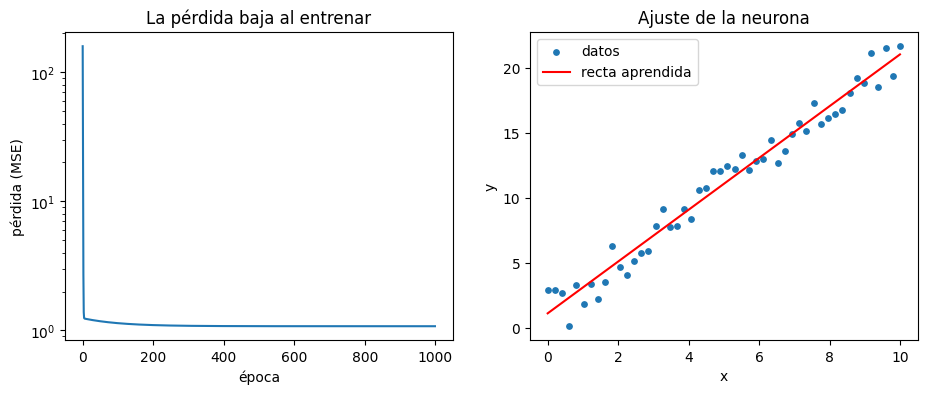

In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(historial_manual)
ejes[0].set_xlabel("época")
ejes[0].set_ylabel("pérdida (MSE)")
ejes[0].set_yscale("log")
ejes[0].set_title("La pérdida baja al entrenar")

ejes[1].scatter(X, y, s=15, label="datos")
ejes[1].plot(X, (w * X + b).detach(), color="red", label="recta aprendida")
ejes[1].set_xlabel("x")
ejes[1].set_ylabel("y")
ejes[1].set_title("Ajuste de la neurona")
ejes[1].legend()

plt.show()

`.detach()` entrega una copia del tensor desconectada del registro de autograd. Hace falta porque matplotlib no puede graficar un tensor que requiere gradiente.

### 10.4 La misma neurona con `nn.Linear`

Lo de arriba funciona, pero con miles de parámetros sería inmanejable. PyTorch trae cada pieza ya hecha:

| A mano | Con PyTorch |
|---|---|
| `w` y `b` con `requires_grad=True` | `nn.Linear(entradas, salidas)` |
| `((y_pred - y) ** 2).mean()` | `nn.MSELoss()` |
| `w -= lr * w.grad` | `optimizer.step()` |
| `w.grad.zero_()` | `optimizer.zero_grad()` |

`nn.Linear(1, 1)` es exactamente una neurona con 1 entrada y 1 salida: crea `w` y `b` por dentro, con valores iniciales aleatorios.

In [24]:
torch.manual_seed(42)

neurona = nn.Linear(in_features=1, out_features=1)

print("peso inicial :", neurona.weight.item())
print("sesgo inicial:", neurona.bias.item())

peso inicial : 0.7645385265350342
sesgo inicial: 0.8300079107284546


`nn.Linear` espera los datos con forma **[ejemplos, características]**. Nuestro `X` tiene forma `[50]`, así que lo pasamos a `[50, 1]` con `unsqueeze`. Lo mismo con `y`, para que tenga la misma forma que las predicciones.

In [25]:
X_col = X.unsqueeze(1)
y_col = y.unsqueeze(1)
print(X.shape, "->", X_col.shape)

torch.Size([50]) -> torch.Size([50, 1])


In [26]:
criterio = nn.MSELoss()
optimizador = torch.optim.SGD(neurona.parameters(), lr=0.01)

historial_nn = []

for epoca in range(1000):
    y_pred = neurona(X_col)             # 1. Predicción
    loss = criterio(y_pred, y_col)      # 2. Pérdida

    optimizador.zero_grad()             # Gradientes en cero
    loss.backward()                     # 3. Gradientes
    optimizador.step()                  # 4. Actualización

    historial_nn.append(loss.item())
    if epoca % 200 == 0:
        print(f"época {epoca:4d}  pérdida={loss.item():8.4f}")

print(f"\nAprendido: w={neurona.weight.item():.3f}, b={neurona.bias.item():.3f}   (real: w=2, b=1)")

época    0  pérdida= 55.7348
época  200  pérdida=  1.0782
época  400  pérdida=  1.0779


época  600  pérdida=  1.0779
época  800  pérdida=  1.0779

Aprendido: w=1.996, b=1.117   (real: w=2, b=1)


Son los mismos cuatro pasos y el resultado es prácticamente el mismo que a mano. Este ciclo de cinco líneas es el **esqueleto de todo entrenamiento en PyTorch**, sea una neurona o una red enorme.

`torch.optim.SGD` es el descenso de gradiente que escribimos antes. Recibe `neurona.parameters()` para saber qué números tiene que ajustar.

**Usar la neurona entrenada.** Para predecir se desactiva el registro de gradientes:

In [27]:
nuevo = torch.tensor([[4.0], [12.0]])     # forma [2, 1]: dos ejemplos, una característica

with torch.no_grad():
    prediccion = neurona(nuevo)

for entrada, salida in zip(nuevo, prediccion):
    print(f"x = {entrada.item():5.1f}  ->  predicción = {salida.item():.2f}   (valor real sin ruido: {2 * entrada.item() + 1:.2f})")

x =   4.0  ->  predicción = 9.10   (valor real sin ruido: 9.00)
x =  12.0  ->  predicción = 25.07   (valor real sin ruido: 25.00)


### 10.5 Neurona con activación para clasificar

Hasta aquí la neurona predice un número cualquiera (**regresión**). Para responder sí/no (**clasificación**) se le añade una activación **sigmoide**, que convierte cualquier valor en un número entre 0 y 1, interpretable como probabilidad:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

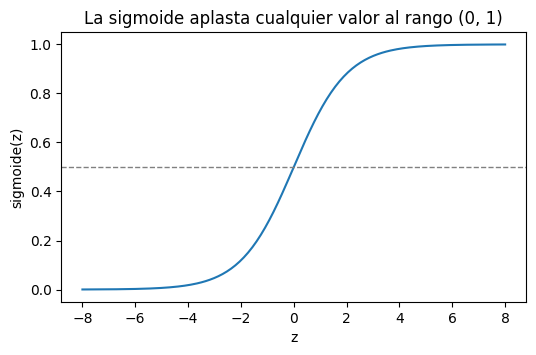

In [28]:
z = torch.linspace(-8, 8, 200)

plt.figure(figsize=(6, 3.5))
plt.plot(z, torch.sigmoid(z))
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xlabel("z")
plt.ylabel("sigmoide(z)")
plt.title("La sigmoide aplasta cualquier valor al rango (0, 1)")
plt.show()

**El problema.** Enseñarle a la neurona la compuerta lógica **AND**: la salida es 1 solo si las dos entradas son 1.

| x1 | x2 | salida |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 0 |
| 1 | 0 | 0 |
| 1 | 1 | 1 |

Esta vez definimos la neurona como una **clase** que hereda de `nn.Module`, que es la forma estándar de escribir modelos en PyTorch:

- En `__init__` se declaran las piezas.
- En `forward` se describe cómo pasan los datos por ellas.

In [29]:
class Neurona(nn.Module):
    def __init__(self, n_entradas):
        super().__init__()
        self.lineal = nn.Linear(n_entradas, 1)

    def forward(self, x):
        z = self.lineal(x)              # combinación lineal
        return torch.sigmoid(z)         # activación


X_and = torch.tensor([[0.0, 0.0],
                      [0.0, 1.0],
                      [1.0, 0.0],
                      [1.0, 1.0]])
y_and = torch.tensor([[0.0], [0.0], [0.0], [1.0]])

torch.manual_seed(42)
modelo = Neurona(n_entradas=2)
print(modelo)

Neurona(
  (lineal): Linear(in_features=2, out_features=1, bias=True)
)


Para clasificación binaria la pérdida habitual es la **entropía cruzada binaria** (`nn.BCELoss`), que castiga fuerte cuando la neurona está muy segura y se equivoca. El ciclo de entrenamiento es idéntico al anterior.

In [30]:
criterio = nn.BCELoss()
optimizador = torch.optim.SGD(modelo.parameters(), lr=1.0)

for epoca in range(2000):
    y_pred = modelo(X_and)
    loss = criterio(y_pred, y_and)

    optimizador.zero_grad()
    loss.backward()
    optimizador.step()

    if epoca % 400 == 0:
        print(f"época {epoca:4d}  pérdida={loss.item():.4f}")

época    0  pérdida=0.6903


época  400  pérdida=0.0424


época  800  pérdida=0.0216
época 1200  pérdida=0.0144


época 1600  pérdida=0.0108


In [31]:
with torch.no_grad():
    probabilidades = modelo(X_and)

print("x1  x2   probabilidad   predicción   esperado")
for entrada, p, real in zip(X_and, probabilidades, y_and):
    print(f"{int(entrada[0])}   {int(entrada[1])}    {p.item():.3f}          {int(p.item() > 0.5)}            {int(real.item())}")

print("\npesos:", modelo.lineal.weight.data, " sesgo:", modelo.lineal.bias.data)

x1  x2   probabilidad   predicción   esperado
0   0    0.000          0            0
0   1    0.010          0            0
1   0    0.010          0            0
1   1    0.986          1            1

pesos: tensor([[8.8262, 8.8262]])  sesgo: tensor([-13.4097])


La probabilidad se convierte en una decisión con un umbral de 0.5.

Fíjate en los parámetros aprendidos: los dos pesos son positivos y el sesgo es negativo y grande. Un solo 1 no alcanza para superar el sesgo; hacen falta los dos. Eso es exactamente la lógica del AND.

**Límite de una sola neurona.** Solo puede separar los datos con una línea recta. Por eso aprende AND y OR, pero no XOR. Para problemas así se combinan muchas neuronas en capas: una red neuronal.

## 11. Guardar y cargar un modelo

Lo que se guarda es el `state_dict`: un diccionario con los parámetros aprendidos. Para cargarlo, primero se crea un modelo con la misma estructura y luego se le cargan los parámetros.

In [32]:
print(modelo.state_dict())

torch.save(modelo.state_dict(), "neurona_and.pth")

modelo_cargado = Neurona(n_entradas=2)
modelo_cargado.load_state_dict(torch.load("neurona_and.pth"))
modelo_cargado.eval()       # modo evaluación: buena costumbre antes de predecir

with torch.no_grad():
    print("predicción para [1, 1]:", modelo_cargado(torch.tensor([[1.0, 1.0]])).item())

OrderedDict([('lineal.weight', tensor([[8.8262, 8.8262]])), ('lineal.bias', tensor([-13.4097]))])
predicción para [1, 1]: 0.9858355522155762


## 12. Resumen

- Un **tensor** es un arreglo de números. Revisa siempre su `shape`, `dtype` y `device`.
- El **producto matricial** (`@`) exige que las dimensiones interiores coincidan.
- **Autograd** calcula derivadas: `requires_grad=True`, luego `.backward()`, y el resultado queda en `.grad`.
- Una **neurona** calcula `w · x + b` y, opcionalmente, aplica una activación.
- **Entrenar** es repetir: predicción, pérdida, `zero_grad()`, `backward()`, `step()`.
- `nn.Linear` crea los parámetros, la función de pérdida mide el error y el optimizador actualiza los parámetros.
- `torch.no_grad()` se usa al predecir.

## Ejercicios

1. En la sección 10.3, cambia `lr` a `0.05` y luego a `0.0001`. ¿Qué pasa con la pérdida en cada caso?
2. Cambia los datos para que sigan la recta $y = -3x + 5$ y comprueba que la neurona encuentra esos valores.
3. Entrena la clase `Neurona` para la compuerta **OR**. ¿En qué se diferencian los parámetros aprendidos de los de AND?
4. Intenta entrenarla para **XOR** (salidas `0, 1, 1, 0`). Observa que la pérdida se estanca y explica por qué.
5. Crea una neurona con 3 entradas con `nn.Linear(3, 1)` y pásale un tensor de forma `[5, 3]`. ¿Qué forma tiene la salida?